# Compare network predictions from TPS, TimeXNet, Dynamic Bayesian Network, and FunChisq - February 3, 2017

Similar to the June 1, 2016 version but saved the Venn diagram figures.  Also adds a comparison to TPS run on the directed TXN output and a comparison between the predicted networks and the EGFR reference pathway nodes.

Similar to June 7, 2016 version but now converts a pair of directed edges in the Dynamic Bayesian Network to an undirected edge after applying a probability threshold.

Similar to June 10, 2016 version but adds FunChisq to the comaprison and removes some older figures.

## Initializations

In [1]:
%pylab inline
import os
from collections import defaultdict
import pyupset as pyu
import pandas as pd
from matplotlib_venn import venn2_unweighted, venn3_unweighted

tps_dir = os.path.join('..','..','synthesis072614')
tps_file = os.path.join(tps_dir,'p-0.01_202dir_cytoscape_genes_092515.txt')

# Same TXN network is in the 2016-05-03-DBN-TXN-TPS-networks directory
txn_file = os.path.join('..','..','TimeXNet','results','020916','net_4.5_0.0','lp_sol_4.5-0.0_nw.sif')
# The same network as tps_file, used solely to verify the parsing is correct
txn_alt_file = os.path.join('..','..','evaluation','2016-05-03-DBN-TXN-TPS-networks','TXN-ALL-directed.sif')

dbn_file = os.path.join('..','..','evaluation','2016-05-03-DBN-TXN-TPS-networks','DBN.tsv')
txn_tps_file = os.path.join('..','..','evaluation','2016-05-03-DBN-TXN-TPS-networks','TXN-ALL-undirected-topo-kinsub-temporal-output.sif')
# Used to assess how TPS temporal constraints detect violations in TXN temporal constraints
txn_tps_dir_file = os.path.join('..','..','evaluation','2016-05-03-DBN-TXN-TPS-networks','TXN-ALL-directed-topo-kinsub-temporal-output.sif')

# EGFR reference pathway nodes
gold_standard_file = os.path.join('..','..','evaluation','2014-10-03','eight-egfr-reference-all.txt')

# Two versions of FunChisq - one with the top 1000 directed edges and one with 500 directed edges
fcs_500_file = os.path.join('..','..','FunChisq','2017-01-09-benchmarking-network-collection','funchisq-500.sif')
fcs_1000_file = os.path.join('..','..','FunChisq','2017-01-09-benchmarking-network-collection','funchisq-1000.sif')

out_dir = os.path.join('..','..','evaluation','2017-02-03-network-overlaps')
if not os.path.exists(out_dir):
    os.makedirs(out_dir)
    print('Created {}'.format(out_dir))

Populating the interactive namespace from numpy and matplotlib


## Load the EGFR reference pathway nodes

In [2]:
gs_df = pd.read_csv(gold_standard_file, header=None, names=['Nodes'])
print 'Loaded %d EGFR reference pathway nodes' % len(gs_df)
gs_df.head()

Loaded 324 EGFR reference pathway nodes


,Nodes
0,1433B_HUMAN
1,1433E_HUMAN
2,1433T_HUMAN
3,4EBP1_HUMAN
4,ABI1_HUMAN


## Helper functions to load the networks
Track directed and undirected edges separately so that they are recognized as different types of predictions.  Use :u: to separate proteins in an undirected edge and :d: for directed edges (signs are ignored).  When creating an undirected edge, sort the protein names.  The node helper function takes the list of edges in a data frame, creates a set of the unique nodes in those edges, and returns a new data frame listing those nodes.

### TPS
Expect 413 edges and 311 nodes.
- Activation, Inhibition, Unknown are directed edges
- None is an undirected edge

### TimeXNet
1073 edges and 626 nodes.  All are treated as directed edges because TimeXNet paper uses the flow direction during the evaluation.  TimeXNet node list has a bug, missing TXD11_HUMAN.
- pp indicates undirected edge in the input PPI network
- pd indicates directed edge in the input PPI network

### Dynamic Bayesian Network (DBN)
Use the PPI prior, max in-degree of 2 version of the network.  1138084 peptide-peptide interactions because self-edges have been removed already.  All peptide-peptide interactions are directed.  Store protein-protein edges by taking the max probability over all corresponding peptide-peptide edges.  There are 490700 = 701^2-701 directed protein-protein edges.  After filtering, will collapse pairs of directed edges into undirected edges.  Ignore edge sign.

### TimeXNet+TPS
Strips the TimeXNet network of its directions and does not filter based on edge flow to obtain a seed network.  Then runs TPS on the undirected TimeXNet-based seed network.  After running TPS, the network has 1063 edges and 622 nodes.

### TimeXNet(directed)+TPS
Retains the TimeXNet flow-based directions and does not filter based on edge flow to obtain a seed network.  Then runs TPS on the directed TimeXNet-based seed network to detect conflicts between the TimeXNet and TPS temporal constraints.  After running TPS, the network has 725 edges and 449 nodes.

### FunChisq
One version initially has 1000 edges, the other 500 edges.  Uses TPS convention that **N** is a directed, unsigned edge.  Collapse pairs of directed edges into undirected edges.

In [3]:
# This parser is for older TPS files
def load_tps(tps_file):
    # Create a list of edges
    edges = list()
    dir_count = 0
    undir_count = 0
    
    with open(tps_file) as tps_f:
        for line in tps_f:
            # Prot1 \t Prot2 \t EdgeType
            parts = line.strip().split('\t')
            if parts[2] == 'Activation' or parts[2] == 'Inhibition' or parts[2] == 'Unknown':
                # Add directed edge in the correct direction
                edges.append('%s:d:%s' % (parts[0], parts[1]))
                dir_count += 1
            elif parts[2] == 'None':
                # Sort the nodes in an undirected edge
                sorted_prots = sorted((parts[0], parts[1]))
                edges.append('%s:u:%s' % (sorted_prots[0], sorted_prots[1]))
                undir_count += 1
            else:
                raise RuntimeError('Invalid edge type')
    
    # Create a data frame
    df = pd.DataFrame(data=edges, columns=['Edges'])
    print 'Loaded %d edges from TPS network, %d directed and %d undirected' % (len(df), dir_count, undir_count)
    return df


def load_txn(txn_file):
    # Create a list of edges
    dir_edges = list()
    pd_count = 0
    
    with open(txn_file) as txn_f:
        for line in txn_f:
            # Prot1 \t EdgeType \t Prot2
            parts = line.strip().split('\t')
            assert parts[1] == 'pp' or parts[1] == 'pd', 'Expected pp or pd'
            # Regardless of whether the edge was originally directed or undirected, use the flow direction
            # as the predicted direction
            dir_edges.append('%s:d:%s' % (parts[0], parts[2]))
            if parts[1] == 'pd':
                pd_count += 1
    
    # Create a data frame
    df = pd.DataFrame(data=dir_edges, columns=['Edges'])
    print 'Loaded %d directed edges from TimeXNet network, %d directions from PPI network' % (len(df), pd_count)
    return df


def load_dbn(dbn_file):
    # Create a mapping of directed protein-protein edges to their max probability
    dir_edges = defaultdict(float)
    self_count = 0
    
    with open(dbn_file) as dbn_f:
        # Skip the header
        dbn_f.readline()
        for line in dbn_f:
            # protein 1 \t protein 2 \t probability \t sign \t peptide 1 \t peptide 2
            parts = line.strip().split('\t')
            # Ignore self-edges, which occur when a multiple peptides map to a protein
            if (not parts[0] == parts[1]):
                edge = '%s:d:%s' % (parts[0], parts[1])
                dir_edges[edge] = max(dir_edges[edge], float(parts[2]))
            else:
                self_count +=1 
        
    # Create a data frame
    df = pd.DataFrame(data=dir_edges.items(), columns=['Edges', 'Probabilities'])
    print 'Loaded %d directed edges from Dynamic Bayesian Network, ignored %d self-edges' % (len(df), self_count)
    return df


def filter_dbn(dbn_df, thresh):
    assert 'Edges' in dbn_df.columns
    assert 'Probabilities' in dbn_df.columns
    dbn_thresh_df = dbn_df[dbn_df['Probabilities'] >= thresh]
    print '%d directed DBN edges with probability >= %s' % (len(dbn_thresh_df), str(thresh))
    
    # Now construct the new edges, swapping pairs of directed edges for undirected edges
    # No longer need the probabilities
    new_edges = set()
    orig_edges = set(dbn_thresh_df['Edges'])
    for edge in dbn_thresh_df['Edges']:
        # Check for the reverse edge
        parts = edge.split(':')
        assert len(parts) == 3, 'Expected two nodes and interaction type'
        assert parts[1] == 'd', 'Expected directed edge'
        rev_edge = '%s:d:%s' % (parts[2], parts[0])
        if rev_edge in orig_edges:
            # Create undirected edge, use a set so we don't have to consider whether this edge was already added
            sorted_prots = sorted((parts[0], parts[2]))
            new_edges.add('%s:u:%s' % (sorted_prots[0], sorted_prots[1]))
        else:
            # Retain the directed edge
            new_edges.add(edge)
            
    df = pd.DataFrame(data=list(new_edges), columns=['Edges'])
    print '%d mixed DBN edges with probability >= %s' % (len(df), str(thresh))
    return df


# This is the appropriate parser for the current TPS file format
def load_txn_tps(tps_file):
    # Create a list of edges
    edges = list()
    dir_count = 0
    undir_count = 0
    
    with open(tps_file) as tps_f:
        for line in tps_f:
            # Prot1 \t EdgeType \t Prot2
            parts = line.strip().split('\t')
            # N and U are different than in the load_tps file.  Here U is undirected and N is none for a
            # directed edge with no edge sign.
            if parts[1] == 'A' or parts[1] == 'I' or parts[1] == 'N':
                # Add directed edge in the correct direction
                edges.append('%s:d:%s' % (parts[0], parts[2]))
                dir_count += 1
            elif parts[1] == 'U':
                # Sort the nodes in an undirected edge
                sorted_prots = sorted((parts[0], parts[2]))
                edges.append('%s:u:%s' % (sorted_prots[0], sorted_prots[1]))
                undir_count += 1
            else:
                raise RuntimeError('Invalid edge type')
    
    # Create a data frame
    df = pd.DataFrame(data=edges, columns=['Edges'])
    print 'Loaded %d edges from TimeXNet + TPS network, %d directed and %d undirected' % (len(df), dir_count, undir_count)
    return df

# Load directed FunChisq edges, then merge pairs of directed edges into undirected edges 
def load_fcs(fcs_file):
    edges = list()
    dir_count = 0
    self_count = 0
    
    with open(fcs_file) as fcs_f:
        for line in fcs_f:
            # Prot1 \t N \t Prot2
            # All edges are directed
            parts = line.strip().split('\t')
            assert parts[1] == 'N', 'All FunChisq edges must be directed'

            # Ignore self-edges, which occur when a multiple peptides map to a protein
            if (not parts[0] == parts[2]):
                # Add directed edge in the correct direction
                edges.append('%s:d:%s' % (parts[0], parts[2]))
                dir_count += 1
            else:
                self_count += 1

    print 'Loaded %d directed edges from FunChisq, ignored %d self-edges' % (dir_count, self_count)
    
    # Combine pairs of directed edges
    new_edges = set()
    orig_edges = set(edges)
    still_dir = 0
    for edge in edges:
        # Check for the reverse edge
        parts = edge.split(':')
        assert len(parts) == 3, 'Expected two nodes and interaction type'
        assert parts[1] == 'd', 'Expected directed edge'
        rev_edge = '%s:d:%s' % (parts[2], parts[0])
        if rev_edge in orig_edges:
            # Create undirected edge, use a set so we don't have to consider whether this edge was already added
            sorted_prots = sorted((parts[0], parts[2]))
            new_edges.add('%s:u:%s' % (sorted_prots[0], sorted_prots[1]))
        else:
            # Retain the directed edge
            new_edges.add(edge)
            still_dir += 1
            
    df = pd.DataFrame(data=list(new_edges), columns=['Edges'])
    print '%d mixed FunChisq edges (%d directed) after merging pairs of directed edges' % (len(df), still_dir)
    return df

def extract_nodes(edge_df):
    node_set = set()
    for edge in edge_df['Edges']:
        parts = edge.split(':')
        assert len(parts) == 3, 'Expected two nodes and interaction type'
        assert parts[1] == 'u' or parts[1] == 'd', 'Expected directed or undirected edge'
        node_set.add(parts[0])
        node_set.add(parts[2])

    print 'Loaded %d nodes' % len(node_set)
    
    # Create a new data frame
    return pd.DataFrame(data=list(node_set), columns=['Nodes'])

## Load the TPS, TimeXNet, DBN, and FunChiSq
Set a DBN probability threshold of >= 0.025, which Ali used to produce a DBN network that is comparable in size to the TPS network (453 nodes).  After threhsolding, pairs of directed edges are converted to undirected edges.  Store a list of all proteins in the mass spec data, including the PSEUDONODE.

Load two versions of the FunChisq network.  One with the top 500 directed edges, one with the top 1000 directed edges.

No longer use the TimeXNet+TPS networks.  See previous notebooks.

In [4]:
tps_df = load_tps(tps_file)
tps_node_df = extract_nodes(tps_df)
print

txn_df = load_txn(txn_file)
txn_node_df = extract_nodes(txn_df)
print

dbn_thresh = 0.025
dbn_df = load_dbn(dbn_file)
dbn_thresh_df = filter_dbn(dbn_df, dbn_thresh)
dbn_thresh_node_df = extract_nodes(dbn_thresh_df)
print

fcs_500_df = load_fcs(fcs_500_file)
fcs_500_node_df = extract_nodes(fcs_500_df)
print

fcs_1000_df = load_fcs(fcs_1000_file)
fcs_1000_node_df = extract_nodes(fcs_1000_df)
print

# The complete DBN network without a threshold can be used to obtain the list of all phosphorylated proteins in the mass spec data
print 'Store list of all proteins in mass spectrometry dataset'
ms_node_df = extract_nodes(dbn_df)

Loaded 413 edges from TPS network, 202 directed and 211 undirected
Loaded 311 nodes

Loaded 1073 directed edges from TimeXNet network, 178 directions from PPI network
Loaded 626 nodes

Loaded 490700 directed edges from Dynamic Bayesian Network, ignored 0 self-edges
587 directed DBN edges with probability >= 0.025
572 mixed DBN edges with probability >= 0.025
Loaded 453 nodes

Loaded 496 directed edges from FunChisq, ignored 4 self-edges
322 mixed FunChisq edges (148 directed) after merging pairs of directed edges
Loaded 129 nodes

Loaded 995 directed edges from FunChisq, ignored 5 self-edges
625 mixed FunChisq edges (255 directed) after merging pairs of directed edges
Loaded 202 nodes

Store list of all proteins in mass spectrometry dataset
Loaded 701 nodes


## Wrapper function for Venn diagrams
Take the same arguments as pyUpSet and return them in a format that can be directly fed to matplotlib-venn

In [5]:
def venn_wrapper(df_dict, col):
    set_list = []
    label_list = []
    for label, df in df_dict.items():
        label_list.append(label)
        set_list.append(set(df[col]))
    
    return set_list, label_list

## Visualize the intersection between the two FunChisq networks
Recall that directed and undirected nodes are not equivalent and will not match during the intersection computation.  Use pyUpSet and traditional Venn diagrams to assess the two visualization options.

C:\Program Files\Anaconda\lib\site-packages\matplotlib\collections.py:590: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  if self._edgecolors == str('face'):


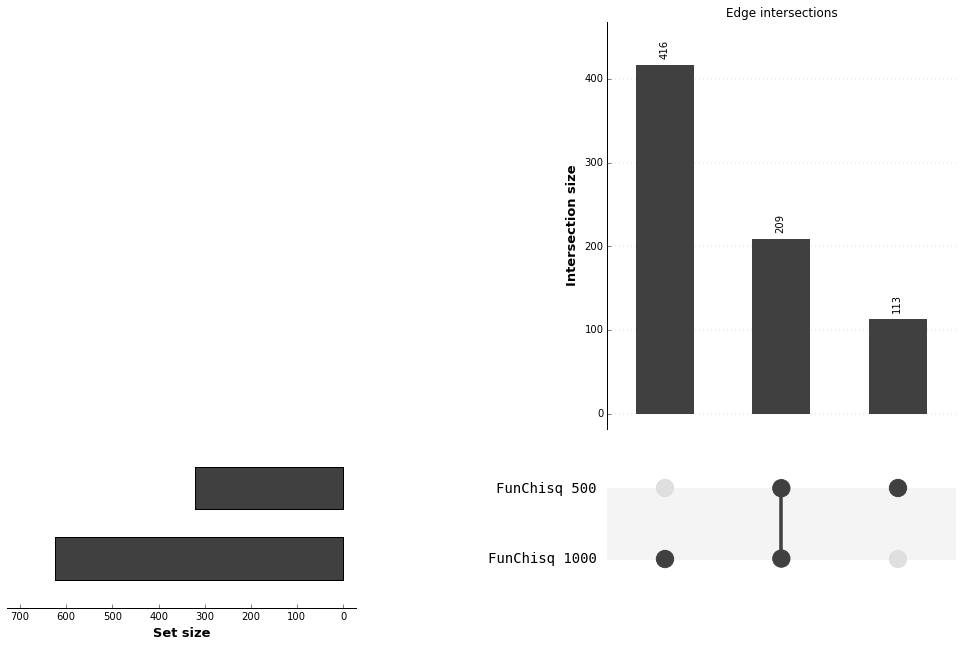

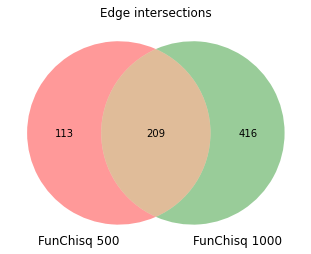

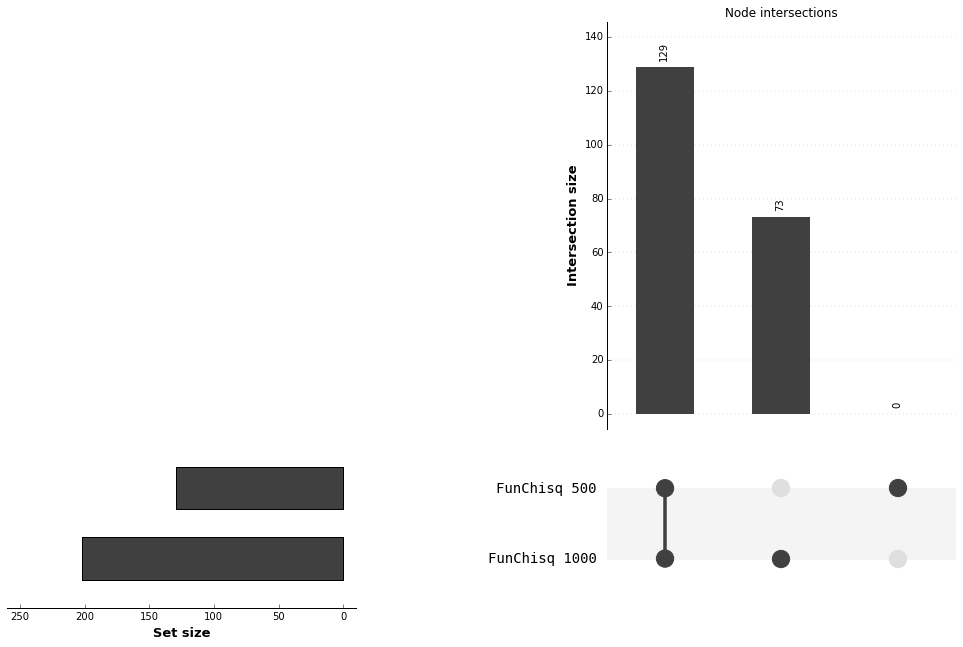

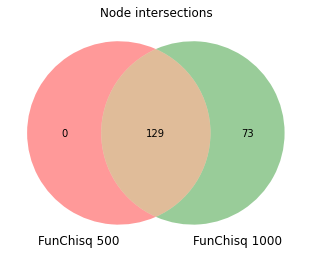

In [6]:
pyu.plot({'FunChisq 500':fcs_500_df, 'FunChisq 1000':fcs_1000_df});
title('Edge intersections');

figure();
title('Edge intersections');
venn2_unweighted(*venn_wrapper({'FunChisq 500':fcs_500_df, 'FunChisq 1000':fcs_1000_df}, 'Edges'))
show()

pyu.plot({'FunChisq 500':fcs_500_node_df, 'FunChisq 1000':fcs_1000_node_df});
title('Node intersections');

figure();
title('Node intersections');
venn2_unweighted(*venn_wrapper({'FunChisq 500':fcs_500_node_df, 'FunChisq 1000':fcs_1000_node_df}, 'Nodes'))
show()

## Visualize the intersection between the TPS, TimeXNet, DBN, and FunChisq networks
Compare edges and nodes.

Recall that directed and undirected nodes are not equivalent and will not match during the intersection computation.  Use pyUpSet and traditional Venn diagrams to assess the two visualization options.

First compare the original three methods, then compare each original method with the two FunChisq networks, then compare the original three with one of the FunChisq networks.

The edge intersections reveal that the majority of edges from each method are unique to that method.  This is accentuated because all of the TPS undirected edges will not match the TimeXNet and DBN directed edges.  However, even TimeXNet and DBN, which only make directed predictions (except the 15 pairs of directed DBN edges converted to undirected), only agree on 14 edges.  We can't argue that any method is better than the other from this analysis.  TPS has very few edges in common with FunChisq at either threshold.  **The different algorithms clearly reason with temporal data in very different ways.**

The node intersections are more similar, but even those are fairly disjoint.  TimeXNet (without a flow filter here) makes more predictions than the others so naturally it has more unique nodes.

109 proteins (potentially including one pseudonode) that are observed in the mass spectrometry do not appear in any of the predicted networks.  This may be reasonable because not all of those proteins have substantial changes in their phosphorylation levels.  DBN and FunChisq can only predict phosphorylated nodes but the TPS and TimeXNet can include other intermediate nodes.

**TODO: decide which figures to save**

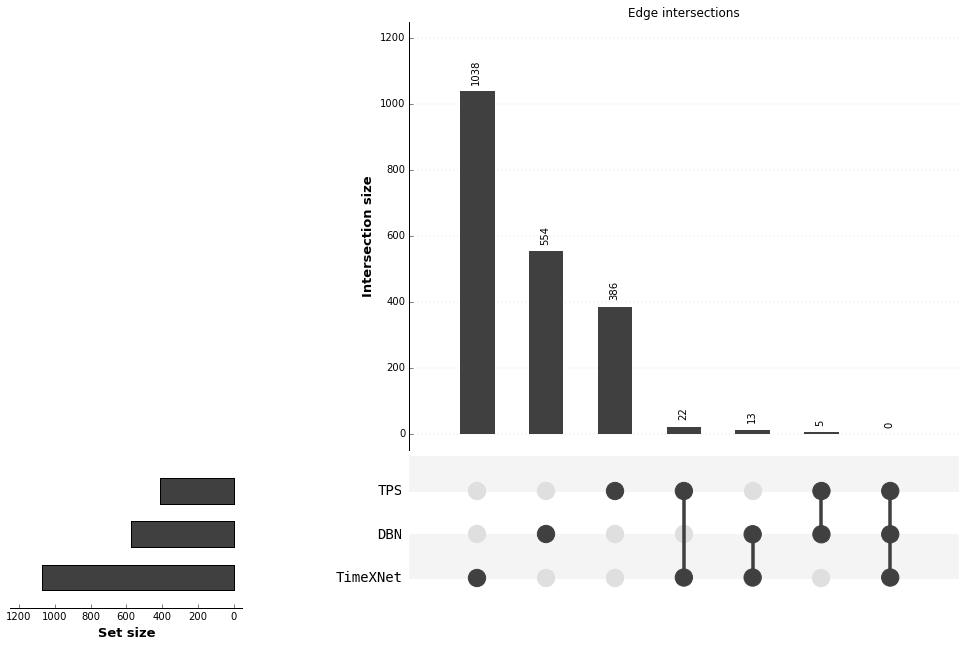

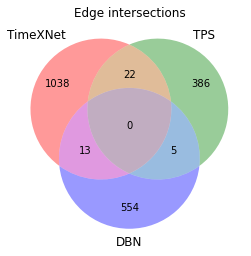

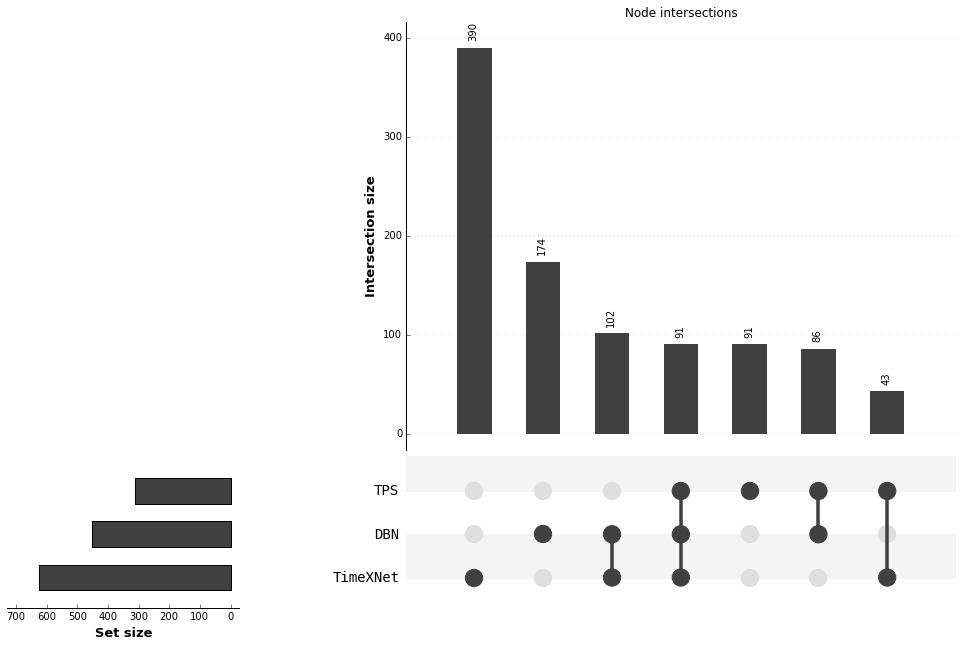

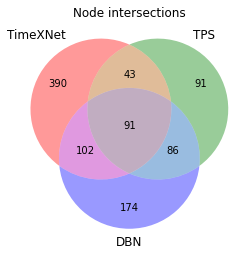

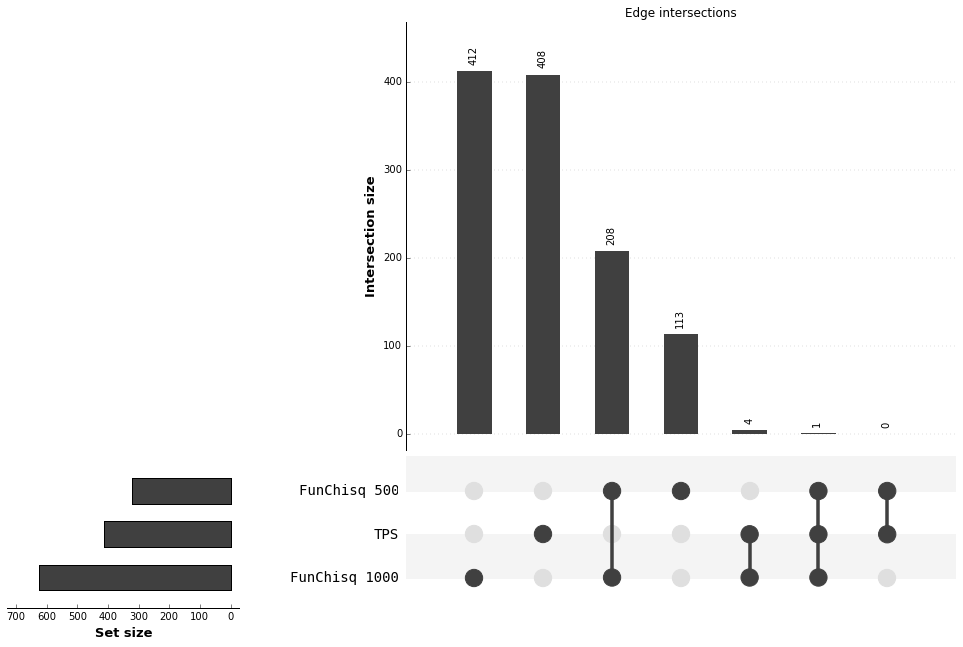

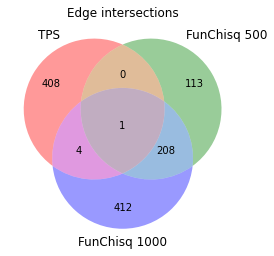

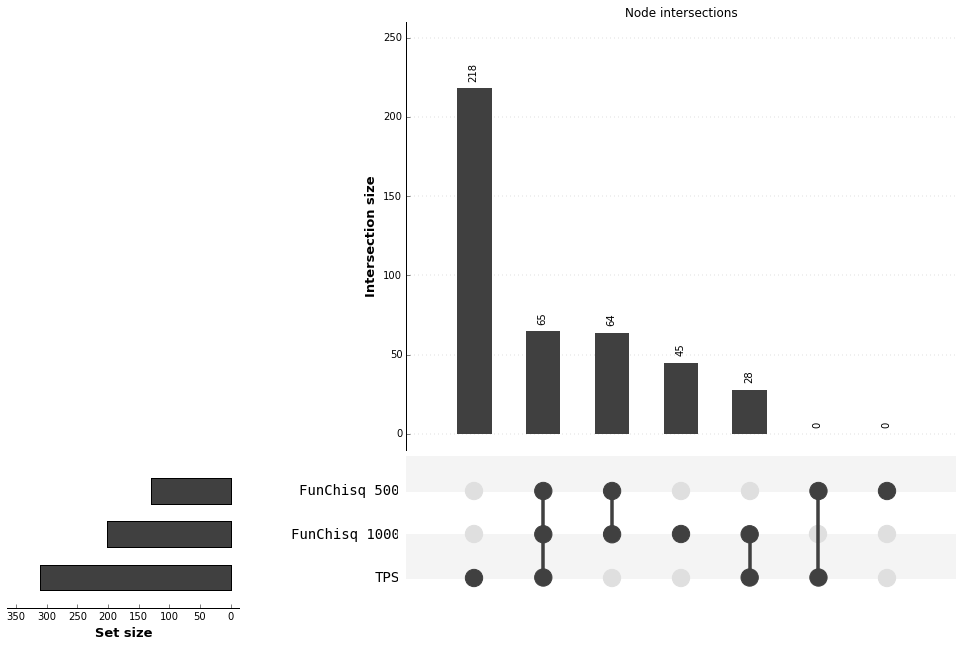

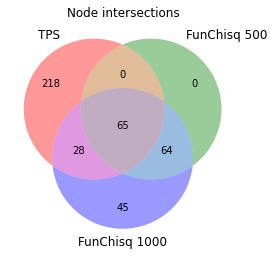

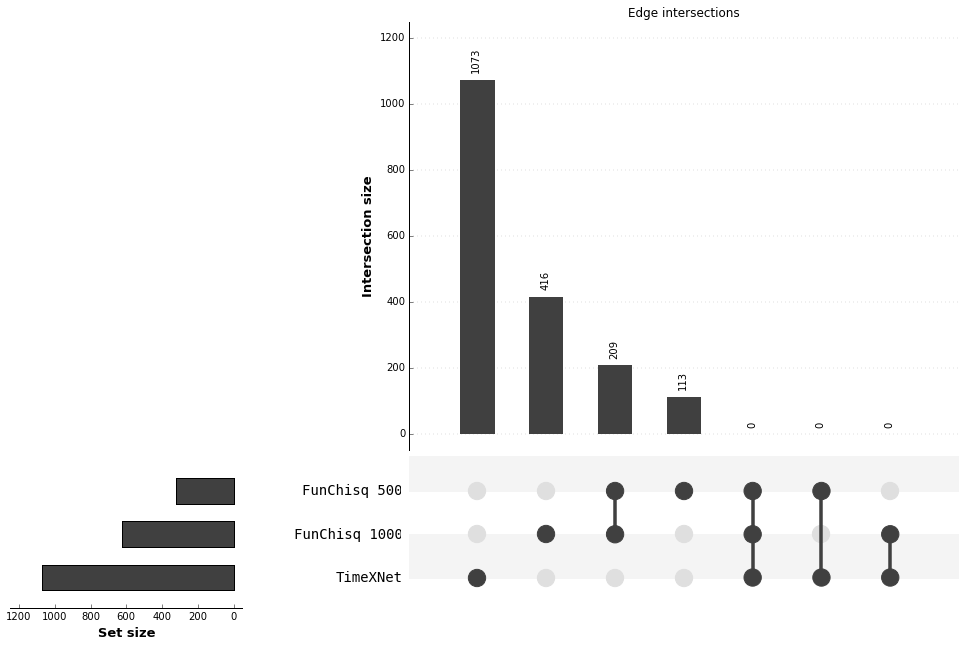

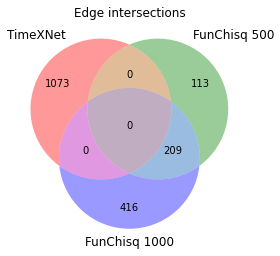

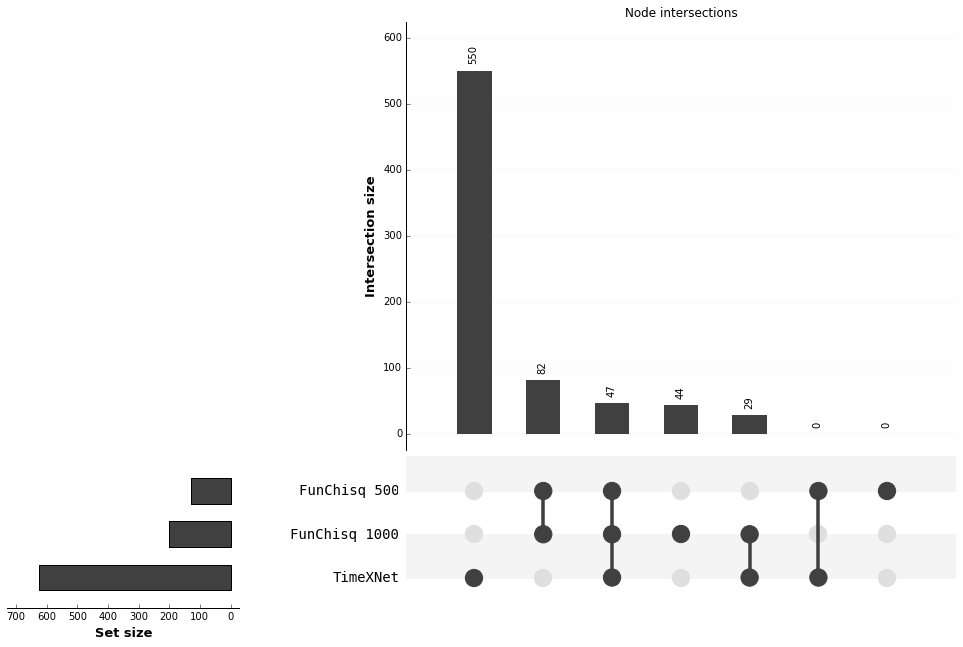

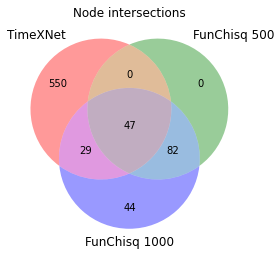

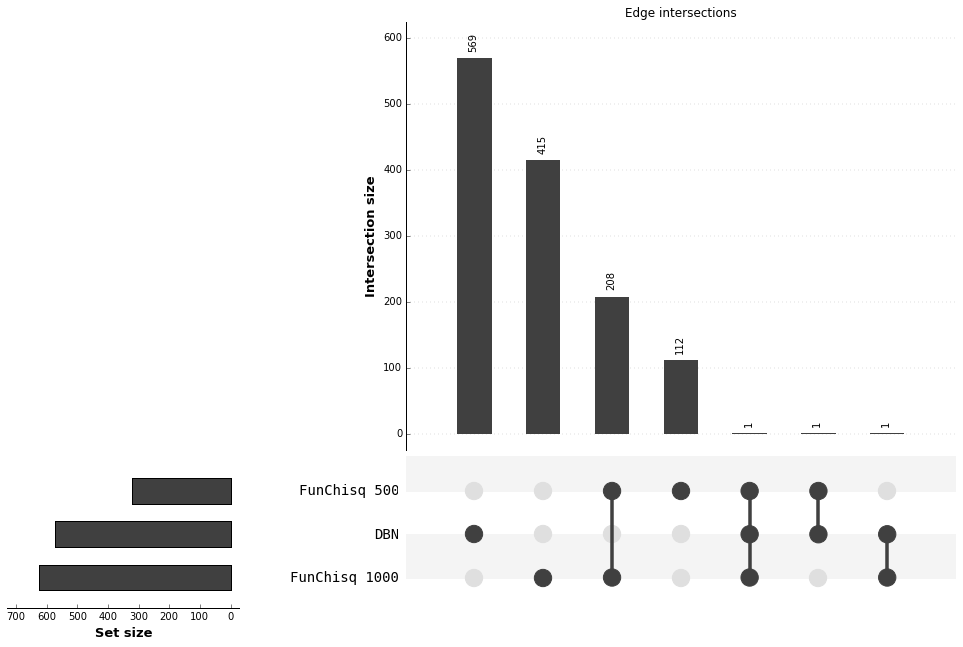

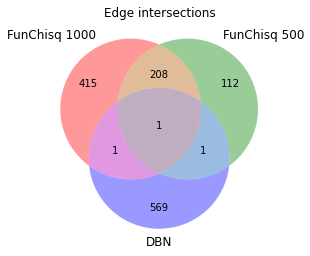

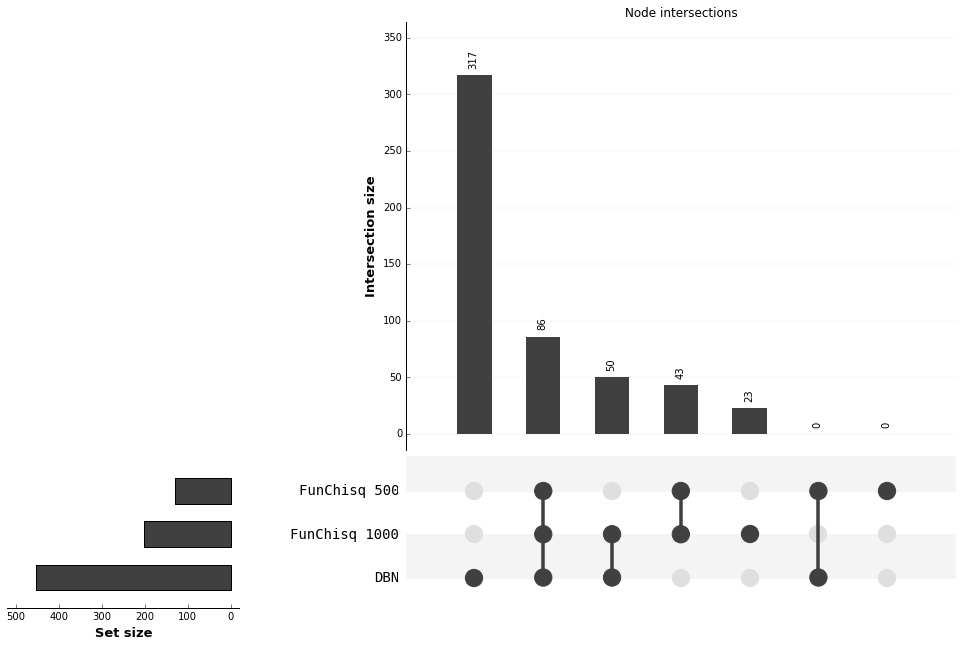

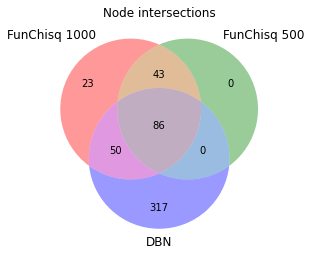

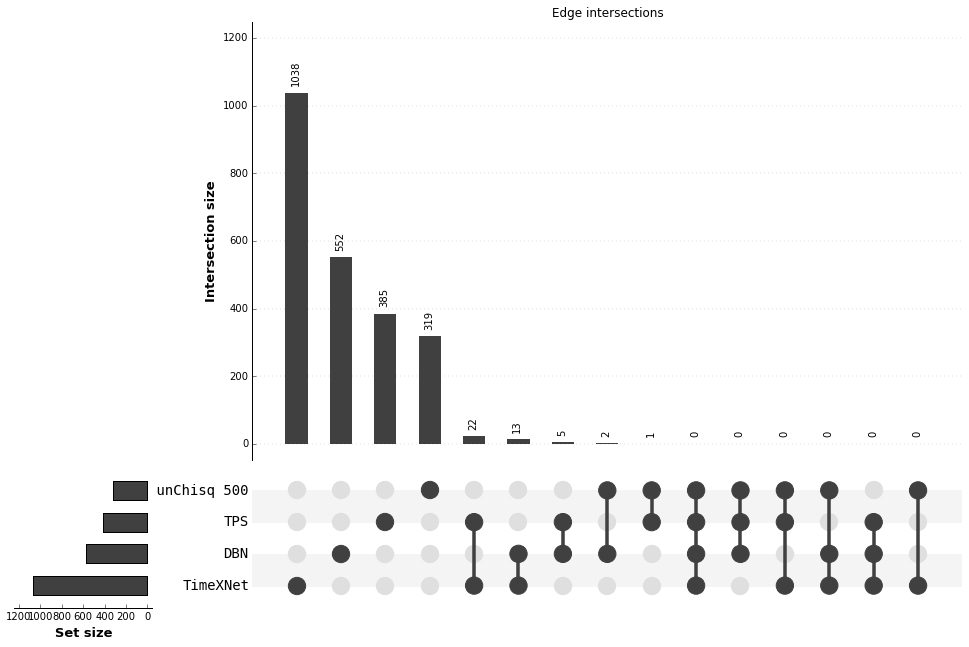

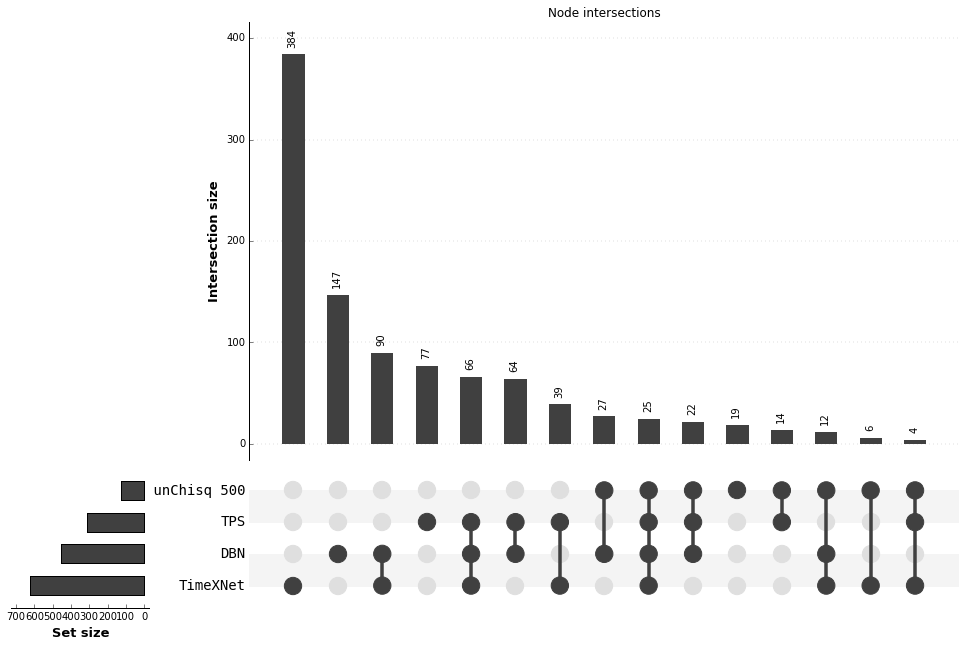

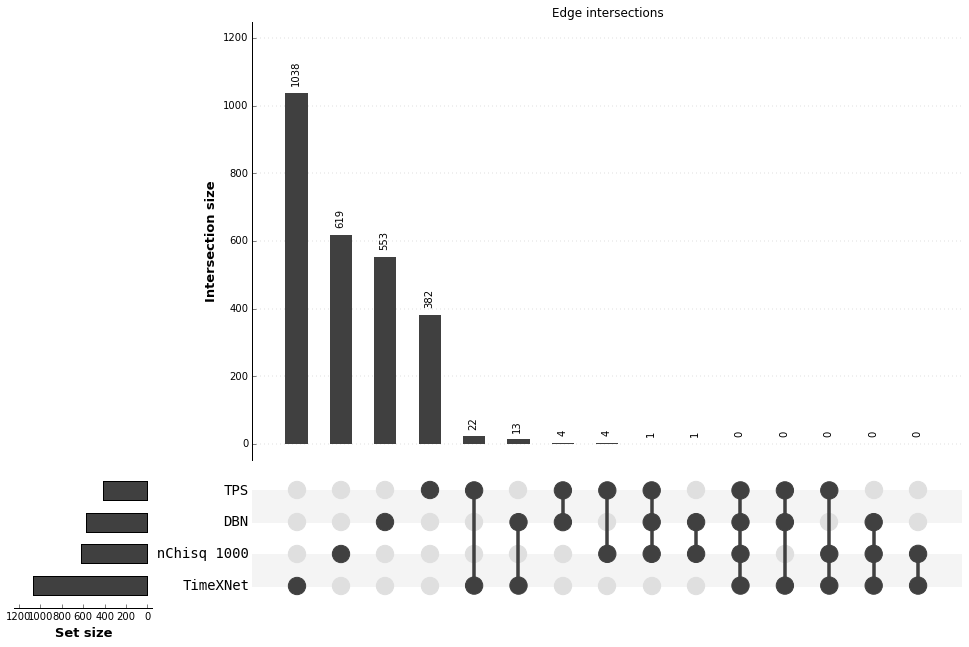

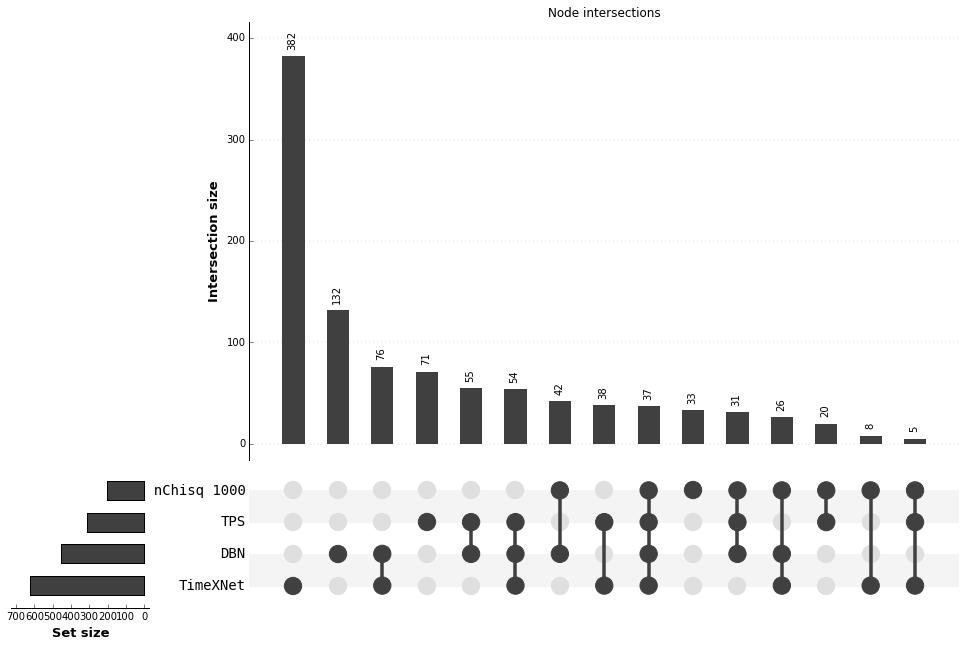

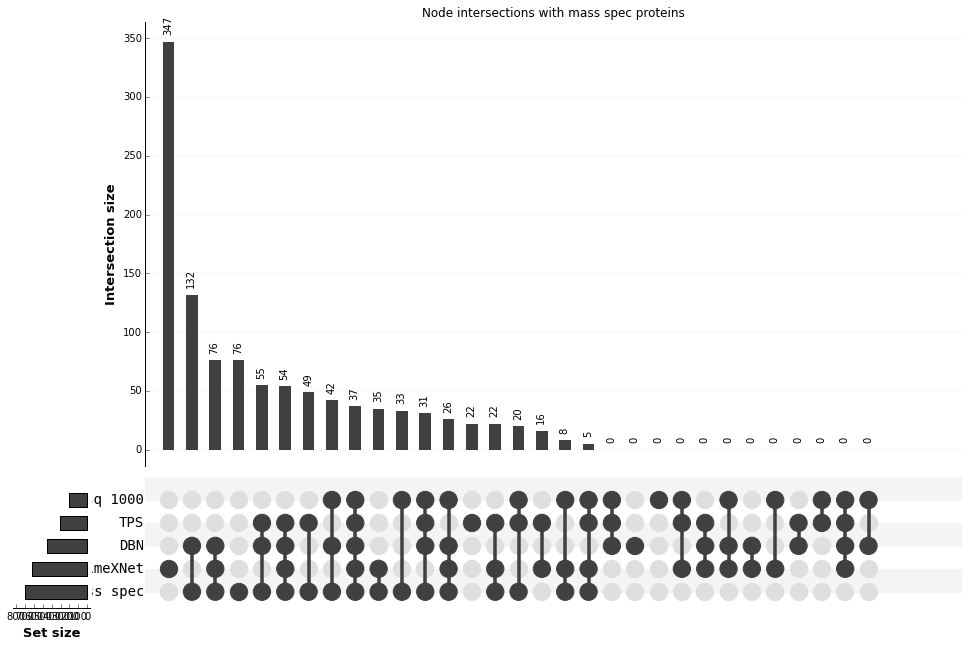

In [7]:
# ------------ Original three networks ------------
pyu.plot({'TPS':tps_df, 'TimeXNet':txn_df, 'DBN':dbn_thresh_df});
title('Edge intersections');

figure();
title('Edge intersections');
venn3_unweighted(*venn_wrapper({'TPS':tps_df, 'TimeXNet':txn_df, 'DBN':dbn_thresh_df}, 'Edges'))
#savefig(os.path.join(out_dir, 'network-edge-overlap.png'), dpi=600, bbox_inches='tight')
#savefig(os.path.join(out_dir, 'network-edge-overlap.svg'), bbox_inches='tight')
show()

pyu.plot({'TPS':tps_node_df, 'TimeXNet':txn_node_df, 'DBN':dbn_thresh_node_df});
title('Node intersections');

figure();
title('Node intersections');
venn3_unweighted(*venn_wrapper({'TPS':tps_node_df, 'TimeXNet':txn_node_df, 'DBN':dbn_thresh_node_df}, 'Nodes'))
#savefig(os.path.join(out_dir, 'network-node-overlap.png'), dpi=600, bbox_inches='tight')
#savefig(os.path.join(out_dir, 'network-node-overlap.svg'), bbox_inches='tight')
show()
# ------------ Original three networks ------------

# ------------ One original network, both FunChisq networks ------------
pyu.plot({'TPS':tps_df, 'FunChisq 500':fcs_500_df, 'FunChisq 1000':fcs_1000_df});
title('Edge intersections');

figure();
title('Edge intersections');
venn3_unweighted(*venn_wrapper({'TPS':tps_df, 'FunChisq 500':fcs_500_df, 'FunChisq 1000':fcs_1000_df}, 'Edges'))
show()

pyu.plot({'TPS':tps_node_df, 'FunChisq 500':fcs_500_node_df, 'FunChisq 1000':fcs_1000_node_df});
title('Node intersections');

figure();
title('Node intersections');
venn3_unweighted(*venn_wrapper({'TPS':tps_node_df, 'FunChisq 500':fcs_500_node_df, 'FunChisq 1000':fcs_1000_node_df}, 'Nodes'))
show()


pyu.plot({'TimeXNet':txn_df, 'FunChisq 500':fcs_500_df, 'FunChisq 1000':fcs_1000_df});
title('Edge intersections');

figure();
title('Edge intersections');
venn3_unweighted(*venn_wrapper({'TimeXNet':txn_df, 'FunChisq 500':fcs_500_df, 'FunChisq 1000':fcs_1000_df}, 'Edges'))
show()

pyu.plot({'TimeXNet':txn_node_df, 'FunChisq 500':fcs_500_node_df, 'FunChisq 1000':fcs_1000_node_df});
title('Node intersections');

figure();
title('Node intersections');
venn3_unweighted(*venn_wrapper({'TimeXNet':txn_node_df, 'FunChisq 500':fcs_500_node_df, 'FunChisq 1000':fcs_1000_node_df}, 'Nodes'))
show()


pyu.plot({'DBN':dbn_thresh_df, 'FunChisq 500':fcs_500_df, 'FunChisq 1000':fcs_1000_df});
title('Edge intersections');

figure();
title('Edge intersections');
venn3_unweighted(*venn_wrapper({'DBN':dbn_thresh_df, 'FunChisq 500':fcs_500_df, 'FunChisq 1000':fcs_1000_df}, 'Edges'))
show()

pyu.plot({'DBN':dbn_thresh_node_df, 'FunChisq 500':fcs_500_node_df, 'FunChisq 1000':fcs_1000_node_df});
title('Node intersections');

figure();
title('Node intersections');
venn3_unweighted(*venn_wrapper({'DBN':dbn_thresh_node_df, 'FunChisq 500':fcs_500_node_df, 'FunChisq 1000':fcs_1000_node_df}, 'Nodes'))
show()
# ------------ One original network, both FunChisq networks ------------

# ------------ Three original networks, one FunChisq network ------------
pyu.plot({'TPS':tps_df, 'TimeXNet':txn_df, 'DBN':dbn_thresh_df, 'FunChisq 500':fcs_500_df});
title('Edge intersections');

pyu.plot({'TPS':tps_node_df, 'TimeXNet':txn_node_df, 'DBN':dbn_thresh_node_df, 'FunChisq 500':fcs_500_node_df});
title('Node intersections');

pyu.plot({'TPS':tps_df, 'TimeXNet':txn_df, 'DBN':dbn_thresh_df, 'FunChisq 1000':fcs_1000_df});
title('Edge intersections');

pyu.plot({'TPS':tps_node_df, 'TimeXNet':txn_node_df, 'DBN':dbn_thresh_node_df, 'FunChisq 1000':fcs_1000_node_df});
title('Node intersections');
# ------------ Three original networks, one FunChisq network ------------


# ------------ Networks and mass spec proteins ------------
pyu.plot({'TPS':tps_node_df, 'TimeXNet':txn_node_df, 'DBN':dbn_thresh_node_df, 'FunChisq 1000':fcs_1000_node_df, 'Mass spec':ms_node_df});
title('Node intersections with mass spec proteins');

## Compare the TPS, TimeXNet, DBN, FunChisq, and mass spectrometry nodes with the EGFR reference pathways
The pyUpSet plots are unreadable with so many rows because all the empty intersections are included.

200 reference pathway nodes (including a few non-protein nodes) are not in the mass spec data or any predicted network.  TimeXNet predicts the most nodes so it is not necessarily surprising that it contains the most unique EGFR reference pathway members.  However, it does have a greater fraction of predicted nodes in the EGFR pathway than TPS, but TPS has a greater fraction than the DBN.  TPS and FunChisq have comparable EGFR overlap ratios, especially at the 500 edge threshold.

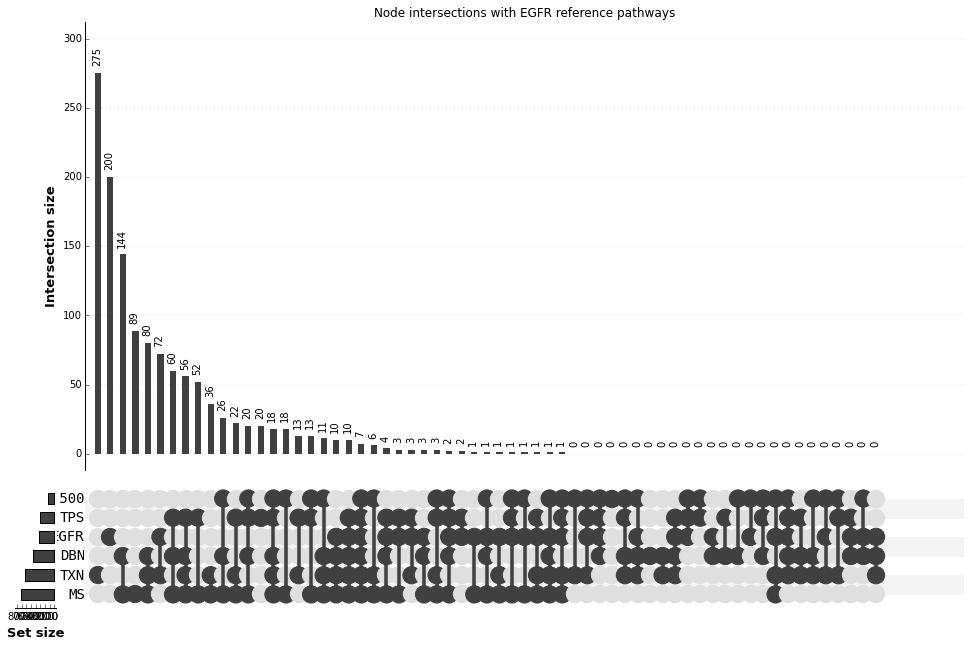

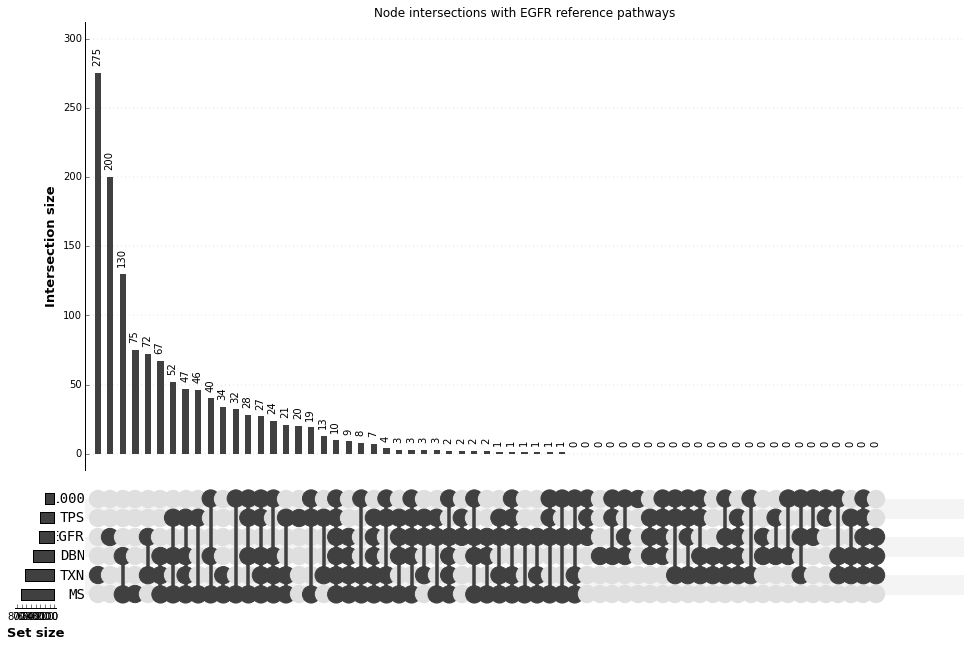

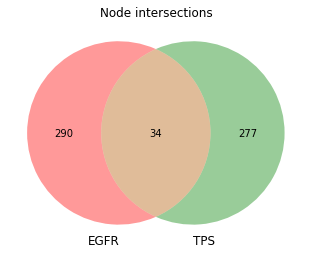

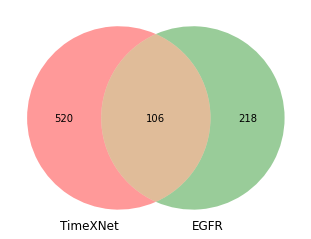

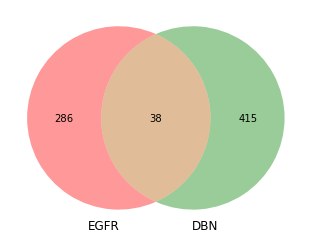

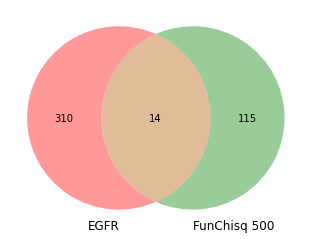

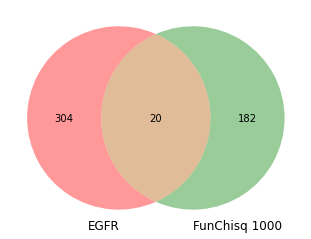

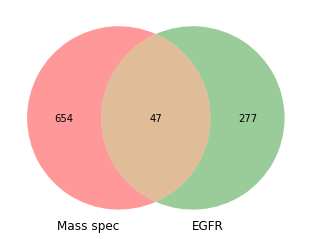

In [8]:
pyu.plot({'TPS':tps_node_df, 'TXN':txn_node_df, 'DBN':dbn_thresh_node_df, 'FunChisq 500':fcs_500_node_df, 'MS':ms_node_df, 'EGFR':gs_df});
title('Node intersections with EGFR reference pathways');

pyu.plot({'TPS':tps_node_df, 'TXN':txn_node_df, 'DBN':dbn_thresh_node_df, 'FunChisq 1000':fcs_1000_node_df, 'MS':ms_node_df, 'EGFR':gs_df});
title('Node intersections with EGFR reference pathways');

figure();
title('Node intersections');
venn2_unweighted(*venn_wrapper({'TPS':tps_node_df, 'EGFR':gs_df}, 'Nodes'))
show()

figure();
venn2_unweighted(*venn_wrapper({'TimeXNet':txn_node_df, 'EGFR':gs_df}, 'Nodes'))
show()

figure();
venn2_unweighted(*venn_wrapper({'DBN':dbn_thresh_node_df, 'EGFR':gs_df}, 'Nodes'))
show()

figure();
venn2_unweighted(*venn_wrapper({'FunChisq 500':fcs_500_node_df, 'EGFR':gs_df}, 'Nodes'))
show()

figure();
venn2_unweighted(*venn_wrapper({'FunChisq 1000':fcs_1000_node_df, 'EGFR':gs_df}, 'Nodes'))
show()

figure();
venn2_unweighted(*venn_wrapper({'Mass spec':ms_node_df, 'EGFR':gs_df}, 'Nodes'))
show()